# Build Forcing Validation - Precipitation
This is a comparison between NLDAS precipitation at Tony Grove and snotel. There is no GAMUT precip data.

In [1]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
#from gdriver.gdriver import get_credentials, getCSVtoPandas
from buildforcing.datasets import PNNLSnotel
import os

In [5]:
# Run parameters
site = 'Tony Grove RS'
latitude = 41.89
longitude = -111.57
start_date = '20150101'
end_date = '20150201'
buildforcing_version = 'v0.1'
#environment = '/home/chriscox/Data/'
environment = 'C:/Users/clmbn/NMT_PhD/data/' # Windows

### Comparison of NLDAS and SNOTEL

In [6]:
nldas_forcing = xr.open_dataset(os.path.join(environment,'nldas',f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

In [7]:
nldas_forcing

<xarray.Dataset> Size: 55kB
Dimensions:    (Date&Time: 768)
Coordinates:
  * Date&Time  (Date&Time) datetime64[ns] 6kB 2015-01-01 ... 2015-02-01T23:00:00
Data variables:
    LWdown     (Date&Time) float64 6kB ...
    PSurf      (Date&Time) float64 6kB ...
    Qair       (Date&Time) float64 6kB ...
    Rainf      (Date&Time) float64 6kB ...
    SWdown     (Date&Time) float64 6kB ...
    Tair       (Date&Time) float64 6kB ...
    Wind_E     (Date&Time) float64 6kB ...
    Wind_N     (Date&Time) float64 6kB ...

In [8]:
# Extract the precipitation data from nldas
nldas_precip = nldas_forcing['Rainf'].to_dataframe()

In [10]:
# Localize the precip data to UTC and then change to America/Denver
nldas_precip.index = nldas_precip.index.tz_localize('UTC').tz_convert('America/Denver')

In [11]:
# Resample to daily
nldas_precip_daily = nldas_precip.resample('D').sum()

In [9]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [12]:
snotel.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
2009-06-08 00:00:00-06:00,NaN,NaN,NaN,NaN,0.0
2009-06-09 00:00:00-06:00,NaN,NaN,NaN,NaN,0.0
2009-06-10 00:00:00-06:00,12.261111,5.394444,8.255556,NaN,0.0
2009-06-11 00:00:00-06:00,13.405556,5.394444,8.255556,NaN,0.0
2009-06-12 00:00:00-06:00,17.411111,4.822222,10.544444,NaN,0.0


<Axes: xlabel='Date&Time'>

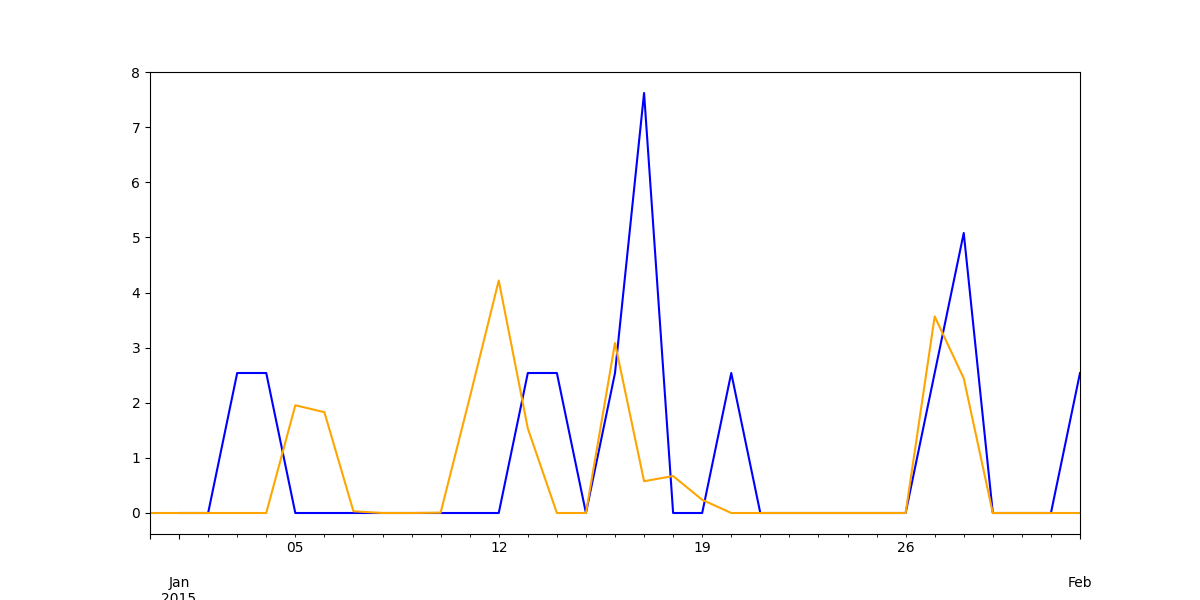

In [13]:
# Plot SNOTEL and NLDAS data
fig, ax = plt.subplots(figsize=(12, 6))
snotel.data.loc[start_date:end_date,'precip_mm'].plot(ax=ax, label='SNOTEL Precipitation', color='blue')
nldas_precip_daily['Rainf'].plot(ax=ax, label='NLDAS Precipitation', color='orange')

- Even when both datasets are daily there is a significant difference in the timing of events.
- Even weekly is going to be problematic.